# Urban Mobility Demand Prediction Using PySpark MLlib

## Project overview

For this project, I am using one Citi Bike trip CSV file to look at when and where people use the bikes. I will clean the data, check a few patterns with Spark SQL, and try a simple model to estimate station-level demand.

The main aim is to use PySpark for data cleaning, demand analysis and machine learning on the trip records. The notebook covers:

- Loading the CSV and checking its columns and data quality.
- Removing records that cannot be used for the analysis.
- Creating time-based columns and counting pickups by station and hour.
- Running a few queries with Spark SQL.
- Training and evaluating a Linear Regression model with Spark MLlib.
- Plotting a small set of charts to make the results easier to understand.


## 1. Set up Spark


In [2]:
import os
import sys
import matplotlib.pyplot as plt

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

spark = SparkSession.builder \
    .appName("Urban_Mobility_Demand_Prediction") \
    .master("local[*]") \
    .config("spark.driver.memory", "2g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print(f"Spark is ready (version {spark.version}).")


Spark is ready (version 3.5.9).


## 2. Check the CSV file

I start by checking the file size, columns, data types, and a few rows. I also check missing values, repeated trip IDs, and the date range covered by the trip timestamps. This gives me an idea of what needs to be handled before analysing demand.

In [3]:
csv_file_path = "202608-citibike-tripdata_6.csv"

df_raw = spark.read.csv(csv_file_path, header=True, inferSchema=True)
raw_count = df_raw.count()
print(f"Rows loaded: {raw_count:,}")


Rows loaded: 246,236


In [4]:
print("Columns and data types:")
df_raw.printSchema()

print("First few rows:")
df_raw.show(5, truncate=False)


Columns and data types:
root
 |-- ride_id: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- started_at: timestamp (nullable = true)
 |-- ended_at: timestamp (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- start_station_id: string (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- end_station_id: string (nullable = true)
 |-- start_lat: double (nullable = true)
 |-- start_lng: double (nullable = true)
 |-- end_lat: double (nullable = true)
 |-- end_lng: double (nullable = true)
 |-- member_casual: string (nullable = true)

First few rows:
+----------------+-------------+-----------------------+-----------------------+--------------------------+----------------+-------------------------+--------------+----------------+-----------------+-----------+------------+-------------+
|ride_id         |rideable_type|started_at             |ended_at               |start_station_name        |start_station_id|end_station_name     

In [5]:
# Check missing values in each column
null_exprs = [
    F.count(F.when(F.col(c).isNull() | (F.col(c) == ""), c)).alias(c)
    for c in df_raw.columns
]
null_counts = df_raw.select(null_exprs).collect()[0].asDict()

print("Missing values:")
for column, count in null_counts.items():
    percent = count / raw_count * 100 if raw_count else 0
    print(f"{column}: {count:,} ({percent:.2f}%)")

distinct_rides = df_raw.select(F.countDistinct("ride_id")).collect()[0][0]
time_bounds = df_raw.select(
    F.min("started_at"), F.max("started_at"),
    F.min("ended_at"), F.max("ended_at")
).collect()[0]

print(f"Unique trip IDs: {distinct_rides:,}")
print(f"Repeated trip IDs: {raw_count - distinct_rides:,}")
print(f"Pickup dates: {time_bounds[0]} to {time_bounds[1]}")
print(f"Drop-off dates: {time_bounds[2]} to {time_bounds[3]}")


Missing values:
ride_id: 0 (0.00%)
rideable_type: 0 (0.00%)
started_at: 0 (0.00%)
ended_at: 0 (0.00%)
start_station_name: 105 (0.04%)
start_station_id: 105 (0.04%)
end_station_name: 0 (0.00%)
end_station_id: 22 (0.01%)
start_lat: 105 (0.04%)
start_lng: 105 (0.04%)
end_lat: 22 (0.01%)
end_lng: 22 (0.01%)
member_casual: 0 (0.00%)
Unique trip IDs: 246,236
Repeated trip IDs: 0
Pickup dates: 2026-08-28 20:00:00.970000 to 2026-08-31 23:58:01.765000
Drop-off dates: 2026-08-28 20:01:52.447000 to 2026-08-31 23:59:56.289000


## 3. Clean the trip records

For station-level pickup analysis, a trip needs a usable start station and valid start and end times. I remove rows with missing start-station details and rows where the end time is not after the start time. I keep both member and casual trips and do not filter by bike type.

In [6]:
# Keep trips with the station details and times needed for this analysis
clean_condition = (
    F.col("start_station_name").isNotNull() &
    (F.col("start_station_name") != "") &
    F.col("start_station_id").isNotNull() &
    F.col("start_lat").isNotNull() &
    F.col("start_lng").isNotNull() &
    (F.col("ended_at") > F.col("started_at"))
)

df_clean = df_raw.filter(clean_condition)
cleaned_count = df_clean.count()
removed_count = raw_count - cleaned_count
retention_rate = cleaned_count / raw_count * 100 if raw_count else 0

print(f"Rows before cleaning: {raw_count:,}")
print(f"Rows kept: {cleaned_count:,}")
print(f"Rows removed: {removed_count:,}")
print(f"Rows kept (%): {retention_rate:.2f}%")

assert raw_count == cleaned_count + removed_count


Rows before cleaning: 246,236
Rows kept: 246,131
Rows removed: 105
Rows kept (%): 99.96%


## 4. Create features and count demand

I use the trip timestamps to create the pickup date, hour, day of the week, and a weekend flag. I also calculate trip duration in minutes.

For the demand analysis, I group trips by station, date, and hour. The `demand` column is the number of pickups recorded for that station during that hour.

In [7]:
# Add a few columns that will help with the analysis
df_trips = df_clean \
    .withColumn("trip_duration_min", F.round((F.unix_timestamp("ended_at") - F.unix_timestamp("started_at")) / 60.0, 2)) \
    .withColumn("pickup_date", F.to_date("started_at")) \
    .withColumn("pickup_hour", F.hour("started_at")) \
    .withColumn("day_of_week", F.dayofweek("started_at")) \
    .withColumn("day_name", F.date_format("started_at", "E")) \
    .withColumn("is_weekend", F.when((F.col("day_of_week") == 1) | (F.col("day_of_week") == 7), 1.0).otherwise(0.0))

df_trips.select(
    "ride_id", "started_at", "pickup_hour", "day_name",
    "is_weekend", "trip_duration_min"
).show(5, truncate=False)

df_trips.groupBy("day_of_week", "day_name").count().orderBy("day_of_week").show()


+----------------+-----------------------+-----------+--------+----------+-----------------+
|ride_id         |started_at             |pickup_hour|day_name|is_weekend|trip_duration_min|
+----------------+-----------------------+-----------+--------+----------+-----------------+
|68A2FD2BC7E2DB2D|2026-08-29 23:28:26.468|23         |Sat     |1.0       |1.28             |
|739523CE755DE11A|2026-08-29 13:43:26.482|13         |Sat     |1.0       |15.28            |
|3A533A67141355B3|2026-08-31 12:46:12.602|12         |Mon     |0.0       |6.25             |
|B07D82B060FF337C|2026-08-30 18:29:34.914|18         |Sun     |1.0       |2.35             |
|C603C3B788201E51|2026-08-30 21:41:30.283|21         |Sun     |1.0       |18.92            |
+----------------+-----------------------+-----------+--------+----------+-----------------+
only showing top 5 rows

+-----------+--------+-----+
|day_of_week|day_name|count|
+-----------+--------+-----+
|          1|     Sun|69637|
|          2|     Mon|

In [8]:
# Count pickups for each station and hour
demand_df = df_trips.groupBy(
    "start_station_id",
    "start_station_name",
    "pickup_date",
    "pickup_hour",
    "day_of_week",
    "is_weekend"
).agg(
    F.count("ride_id").alias("demand"),
    F.round(F.avg("start_lat"), 6).alias("lat"),
    F.round(F.avg("start_lng"), 6).alias("lng")
)

total_demand_obs = demand_df.count()
print(f"Total Station-Hour Observations: {total_demand_obs:,}")

print("\nStation-Hour Demand Statistical Profile:")
demand_df.describe("demand").show()

print("Sample Station-Hour Demand Records:")
demand_df.show(5, truncate=False)

Total Station-Hour Observations: 76,262

Station-Hour Demand Statistical Profile:
+-------+-----------------+
|summary|           demand|
+-------+-----------------+
|  count|            76262|
|   mean|3.227439616060423|
| stddev|3.364745912885438|
|    min|                1|
|    max|               51|
+-------+-----------------+

Sample Station-Hour Demand Records:
+----------------+-----------------------------+-----------+-----------+-----------+----------+------+---------+----------+
|start_station_id|start_station_name           |pickup_date|pickup_hour|day_of_week|is_weekend|demand|lat      |lng       |
+----------------+-----------------------------+-----------+-----------+-----------+----------+------+---------+----------+
|5430.10         |6 Ave & Walker St            |2026-08-29 |13         |7          |1.0       |4     |40.719792|-74.005224|
|3359.03         |Linden Blvd & Nostrand Ave   |2026-08-31 |12         |2          |0.0       |1     |40.65272 |-73.94994 |
|5847.10 

## 5. Queries with Spark SQL


In [9]:
# Make the DataFrame available to Spark SQL
df_trips.createOrReplaceTempView("trips_view")

print("--- SQL Query 1: Top 10 Busiest Origin Stations ---")
spark.sql("""
    SELECT 
        start_station_name, 
        COUNT(*) AS total_trips,
        ROUND(AVG(trip_duration_min), 2) AS avg_duration_min
    FROM trips_view
    GROUP BY start_station_name
    ORDER BY total_trips DESC
    LIMIT 10
""").show(truncate=False)

print("--- SQL Query 2: System-wide Hourly Trip Distribution ---")
spark.sql("""
    SELECT 
        pickup_hour, 
        COUNT(*) AS total_trips,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS pct_of_total
    FROM trips_view
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""").show(24, truncate=False)

print("--- SQL Query 3: Weekday vs Weekend Comparison ---")
spark.sql("""
    SELECT 
        CASE WHEN is_weekend = 1.0 THEN 'Weekend' ELSE 'Weekday' END AS day_type,
        COUNT(*) AS total_trips,
        COUNT(DISTINCT pickup_date) AS distinct_days,
        ROUND(COUNT(*) / COUNT(DISTINCT pickup_date), 1) AS avg_trips_per_day,
        ROUND(AVG(trip_duration_min), 2) AS avg_duration_min
    FROM trips_view
    GROUP BY is_weekend
""").show(truncate=False)

--- SQL Query 1: Top 10 Busiest Origin Stations ---
+------------------------------+-----------+----------------+
|start_station_name            |total_trips|avg_duration_min|
+------------------------------+-----------+----------------+
|Central Park S & 6 Ave        |772        |28.33           |
|Norfolk St & Broome St        |769        |12.5            |
|W 21 St & 6 Ave               |755        |12.05           |
|Pier 61 at Chelsea Piers      |747        |14.44           |
|Metropolitan Ave & Bedford Ave|744        |12.55           |
|10 Ave & W 14 St              |714        |19.72           |
|E 17 St & Broadway            |685        |11.43           |
|Carmine St & 6 Ave            |683        |13.46           |
|S 4 St & Wythe Ave            |675        |13.18           |
|Clinton St & Grand St         |661        |10.55           |
+------------------------------+-----------+----------------+

--- SQL Query 2: System-wide Hourly Trip Distribution ---
+-----------+--------

## 6. Train a Linear Regression model with MLlib

The model tries to estimate the number of pickups for a station-hour record. I use the available time and location features as inputs and `demand` as the value to predict.

The split is based on dates, with earlier records used for training and a later date held out for testing. This is closer to predicting future demand than randomly mixing records. The exact dates available in the CSV should be checked when running this section.

In [12]:
# Use earlier dates for training and the final date for testing
train_data = demand_df.filter(F.col("pickup_date") < "2026-08-31")
test_data = demand_df.filter(F.col("pickup_date") == "2026-08-31")

train_count = train_data.count()
test_count = test_data.count()

print(f"Training rows: {train_count:,}")
print(f"Testing rows: {test_count:,}")

feature_cols = ["pickup_hour", "day_of_week", "is_weekend", "lat", "lng"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

train_vec = assembler.transform(train_data)
test_vec = assembler.transform(test_data)

lr = LinearRegression(featuresCol="features", labelCol="demand", predictionCol="prediction")
lr_model = lr.fit(train_vec)

print(f"Model intercept: {lr_model.intercept:.4f}")
print("Model coefficients:")
for feat, coef in zip(feature_cols, lr_model.coefficients):
    print(f"{feat}: {coef:.4f}")


Training rows: 52,581
Testing rows: 23,681
Model intercept: -2366.4915
Model coefficients:
pickup_hour: 0.0699
day_of_week: 0.0660
is_weekend: 0.9940
lat: 2.2986
lng: -30.7470


## 7. Check the model results

I use RMSE, MAE, and R² to see how close the predictions are to the actual demand values. No single score tells the whole story, so I will look at the three metrics together. A low or negative R² would mean this model does not explain the variation in demand well.

In [13]:
# Get predictions for the test data and keep them for the evaluation and chart below
test_predictions = lr_model.transform(test_vec).cache()
test_predictions.count()  # Run the prediction once so later cells can reuse the result

rmse_eval = RegressionEvaluator(labelCol="demand", predictionCol="prediction", metricName="rmse")
mae_eval = RegressionEvaluator(labelCol="demand", predictionCol="prediction", metricName="mae")
r2_eval = RegressionEvaluator(labelCol="demand", predictionCol="prediction", metricName="r2")

rmse_val = rmse_eval.evaluate(test_predictions)
mae_val = mae_eval.evaluate(test_predictions)
r2_val = r2_eval.evaluate(test_predictions)

print("Model evaluation on the test data")
print(f"RMSE: {rmse_val:.4f}")
print(f"MAE:  {mae_val:.4f}")
print(f"R²:   {r2_val:.4f}")

print("\nA few predictions compared with actual demand:")
test_predictions.select(
    "start_station_name",
    "pickup_hour",
    "demand",
    F.round("prediction", 2).alias("predicted_demand")
).show(10, truncate=False)


Model evaluation on the test data
RMSE: 3.3443
MAE:  1.9590
R²:   0.0480

A few predictions compared with actual demand:
+-----------------------------+-----------+------+----------------+
|start_station_name           |pickup_hour|demand|predicted_demand|
+-----------------------------+-----------+------+----------------+
|Linden Blvd & Nostrand Ave   |12         |1     |1.66            |
|Greenwich St & Christopher St|16         |4     |3.9             |
|8 Ave & W 27 St              |11         |7     |3.25            |
|Parkside Ave & Ocean Ave     |22         |1     |2.74            |
|Greenwich St & Christopher St|8          |7     |3.34            |
|Parkside Ave & Ocean Ave     |10         |3     |1.9             |
|Sterling Pl & Classon Ave    |19         |3     |2.52            |
|38 Ave & 29 St               |15         |3     |1.61            |
|8 Ave & W 27 St              |9          |10    |3.11            |
|Willoughby Ave & Wyckoff Ave |19         |4     |1.4          

## 8. Charts


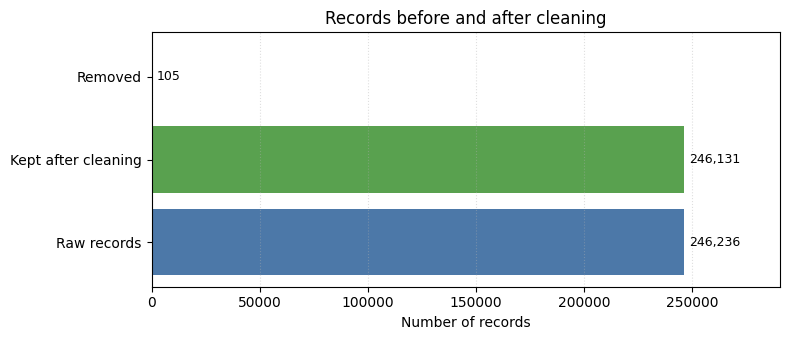

In [14]:
# Chart 1: Records before and after cleaning
fig, ax = plt.subplots(figsize=(8, 3.5))
stages = ["Raw records", "Kept after cleaning", "Removed"]
counts = [raw_count, cleaned_count, removed_count]

bars = ax.barh(stages, counts, color=["#4c78a8", "#59a14f", "#e15759"])
ax.set_xlabel("Number of records")
ax.set_title("Records before and after cleaning")
ax.grid(axis="x", linestyle=":", alpha=0.4)
for bar, value in zip(bars, counts):
    ax.text(value + max(raw_count * 0.01, 1), bar.get_y() + bar.get_height()/2,
            f"{value:,}", va="center", fontsize=9)
ax.set_xlim(0, max(raw_count * 1.18, 1))
plt.tight_layout()
plt.show()


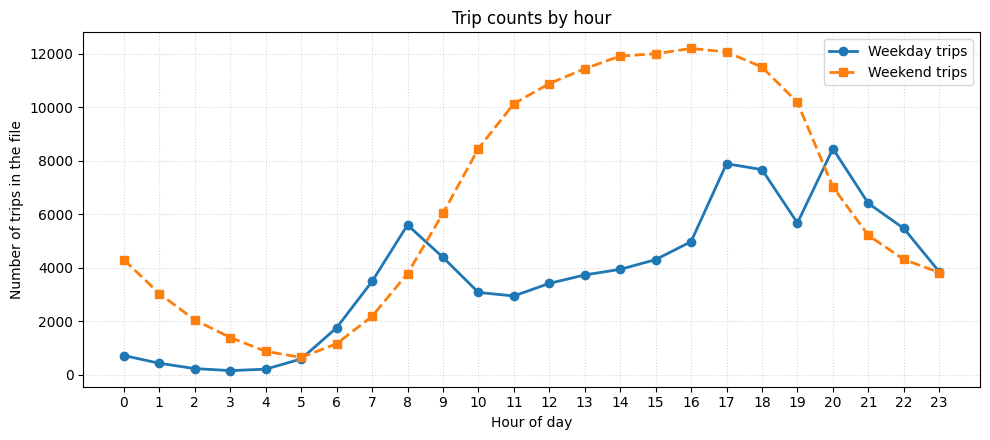

In [15]:
# Chart 2: Trips by hour for weekdays and weekends
hourly_rows = (
    df_trips.groupBy("pickup_hour", "is_weekend")
    .agg(F.count("ride_id").alias("trip_count"))
    .orderBy("pickup_hour", "is_weekend")
    .collect()
)

weekday_counts = {int(r["pickup_hour"]): int(r["trip_count"]) for r in hourly_rows if r["is_weekend"] == 0.0}
weekend_counts = {int(r["pickup_hour"]): int(r["trip_count"]) for r in hourly_rows if r["is_weekend"] == 1.0}
hours = list(range(24))
weekday_values = [weekday_counts.get(h, 0) for h in hours]
weekend_values = [weekend_counts.get(h, 0) for h in hours]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hours, weekday_values, marker="o", linewidth=2, label="Weekday trips")
ax.plot(hours, weekend_values, marker="s", linewidth=2, linestyle="--", label="Weekend trips")
ax.set_title("Trip counts by hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of trips in the file")
ax.set_xticks(hours)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


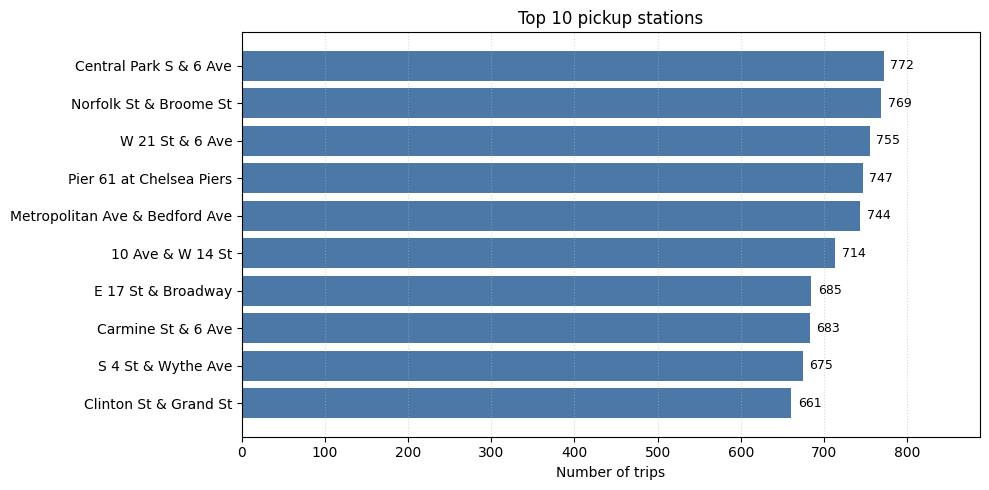

In [16]:
# Chart 3: Ten stations with the most recorded pickups
top10_rows = (
    df_trips.groupBy("start_station_name")
    .count()
    .orderBy(F.col("count").desc())
    .limit(10)
    .collect()
)

station_names = [r["start_station_name"] for r in reversed(top10_rows)]
station_trips = [int(r["count"]) for r in reversed(top10_rows)]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(station_names, station_trips, color="#4c78a8")
ax.set_xlabel("Number of trips")
ax.set_title("Top 10 pickup stations")
ax.grid(axis="x", linestyle=":", alpha=0.5)
for bar, value in zip(bars, station_trips):
    ax.text(value + max(station_trips) * 0.01, bar.get_y() + bar.get_height()/2,
            f"{value:,}", va="center", fontsize=9)
ax.set_xlim(0, max(station_trips) * 1.15 if station_trips else 1)
plt.tight_layout()
plt.show()


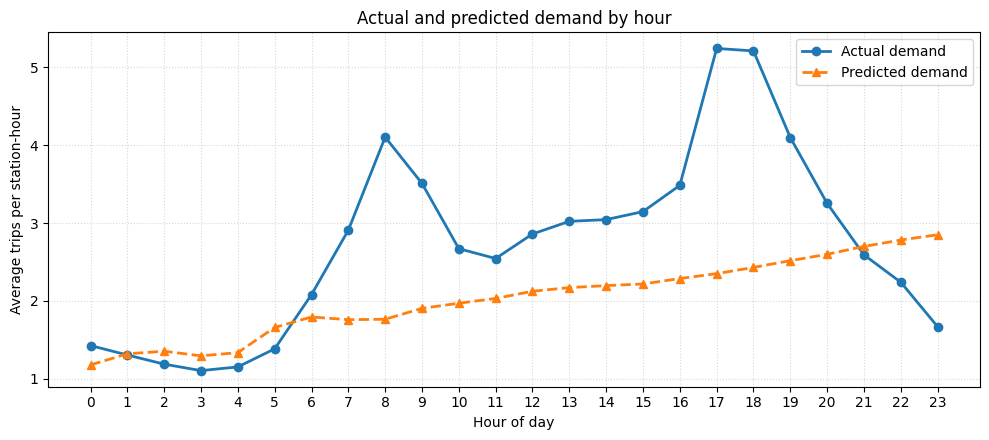

In [17]:
# Chart 4: Compare average actual and predicted demand by hour
hourly_perf = (
    test_predictions.groupBy("pickup_hour")
    .agg(
        F.avg("demand").alias("avg_actual"),
        F.avg("prediction").alias("avg_predicted")
    )
    .orderBy("pickup_hour")
    .collect()
)

hours = [int(r["pickup_hour"]) for r in hourly_perf]
actual_vals = [float(r["avg_actual"]) for r in hourly_perf]
pred_vals = [float(r["avg_predicted"]) for r in hourly_perf]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hours, actual_vals, marker="o", linewidth=2, label="Actual demand")
ax.plot(hours, pred_vals, marker="^", linewidth=2, linestyle="--", label="Predicted demand")
ax.set_title("Actual and predicted demand by hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average trips per station-hour")
ax.set_xticks(range(24))
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


## 9. Conclusion and limitations

In this project, I used PySpark to load and clean the trip records, create station-hour demand counts, run SQL queries, and analyse the data with Spark SQL. I also trained a Linear Regression model with Spark MLlib and checked its predictions using RMSE, MAE, and R².

The final conclusions should be based on the numbers and charts produced when the notebook is run. This dataset covers only a short period, so its patterns may not represent the whole year. The model also uses a small set of features and may miss factors such as weather, special events, or changes in transport services. These are limits of the current project, not things this notebook measures.

In [18]:
# Stop Spark when the notebook is finished
spark.stop()
print("PySpark Session terminated cleanly.")

PySpark Session terminated cleanly.
